# AML Screening of FDA-Approved Small-Molecule Drugs

This notebook applies the trained DAVIS drug–target affinity models to an **exploratory Acute Myeloid Leukemia (AML) drug-repurposing screen**.

The screening data are built from primary/curated sources:

- **AML target selection:** the seven targets discussed in the supplied AML therapeutic-target review
- **Protein sequences:** reviewed human UniProtKB/Swiss-Prot entries retrieved through the UniProt REST API
- **Approved-drug source:** the official FDA Orange Book downloadable data
- **Chemical structures:** PubChem PUG REST
- **Structure validation:** RDKit

Two trained DAVIS models are used:

1. the best-performing DAVIS baseline model on the random test split;
2. the advanced GINE + frozen ESM-2 + CNN + bidirectional cross-attention model.

The output is a computational ranking only. It does **not** establish experimental binding, clinical efficacy, or a new AML indication.

## Notebook workflow

```text
AML target review
      │
      ▼
7 AML targets
BCL2, FLT3, IDH1, IDH2, Menin, CD123, CD47
      │
      ▼
Reviewed human UniProt entries
      │
      ├── accession
      ├── gene
      ├── protein name
      └── canonical protein sequence
      │
      ▼
aml_targets.csv


FDA Orange Book
      │
      ▼
Current RX / OTC approved products
      │
      ▼
Unique active ingredients
      │
      ▼
PubChem PUG REST
      │
      ├── CID
      ├── SMILES
      ├── InChIKey
      ├── molecular formula
      └── molecular weight
      │
      ▼
RDKit structure standardisation
      │
      ▼
candidate_drugs.csv


Candidate drugs × 7 AML targets
              │
              ├─────────────────────────────┐
              ▼                             ▼
 Best DAVIS baseline                 Advanced DAVIS model
 GCN/GAT/GIN + CNN                   GINE + ESM-2 + CNN
                                     + cross-attention
              │                             │
              └──────────────┬──────────────┘
                             ▼
                     Predicted pKd
                             │
                             ▼
                  Model-specific ranks
                             │
                             ▼
                     Consensus ranking
                             │
            ┌────────────────┼─────────────────┐
            ▼                ▼                 ▼
        Top 20 pairs    Top 10/target     Top 20 unique drugs
                             │
                             ▼
                 Save screening outputs
```

The five targets **BCL2, FLT3, IDH1, IDH2 and MEN1** are treated as the main small-molecule screening targets.  
**CD123/IL3RA and CD47** are retained as exploratory targets because the reviewed AML therapeutic strategies for these cell-surface proteins are often antibody- or cell-therapy based.

In [1]:
# ============================================================
# COLAB SETUP — DRIVE + GITHUB + PERMANENT RESULTS
# ============================================================

from google.colab import drive, userdata
from pathlib import Path

import base64
import os
import shutil
import subprocess
import torch


# ------------------------------------------------------------
# 1. Mount Google Drive
# ------------------------------------------------------------

drive.mount(
    "/content/drive",
    force_remount=False,
)


# ------------------------------------------------------------
# 2. Project settings
# ------------------------------------------------------------

GITHUB_REPO = (
    "https://github.com/"
    "Thebluesky303/"
    "msc-dissertation-drug-repurposing.git"
)

BRANCH = "final-aml-gnn-dta"

REPO_DIR = Path(
    "/content/final-msc-dissertation-drug-repurposing"
)

DRIVE_PROJECT = Path(
    "/content/drive/MyDrive/"
    "final-msc-dissertation-drug-repurposing"
)

DRIVE_RESULTS = (
    DRIVE_PROJECT / "results"
)


# ------------------------------------------------------------
# 3. Create permanent Drive folders
# ------------------------------------------------------------

result_folders = [
    "metrics",
    "predictions",
    "figures",
    "checkpoints",
    "esm_embeddings",
    "validation",
    "validation_cache",
]

DRIVE_PROJECT.mkdir(
    parents=True,
    exist_ok=True,
)

DRIVE_RESULTS.mkdir(
    parents=True,
    exist_ok=True,
)

for folder_name in result_folders:
    (
        DRIVE_RESULTS / folder_name
    ).mkdir(
        parents=True,
        exist_ok=True,
    )


# ------------------------------------------------------------
# 4. Read GitHub token from Colab Secrets
# ------------------------------------------------------------

token = userdata.get(
    "colab-dissertation"
)

if not token:
    raise ValueError(
        "GITHUB_TOKEN was not found in Colab Secrets."
    )

auth = base64.b64encode(
    f"x-access-token:{token}".encode()
).decode()

git_auth = (
    f"AUTHORIZATION: basic {auth}"
)


# ------------------------------------------------------------
# 5. Clone repository if it does not exist
#    Otherwise update the existing clone
# ------------------------------------------------------------

if not (
    REPO_DIR / ".git"
).exists():

    print(
        "Cloning repository..."
    )

    subprocess.run(
        [
            "git",
            "-c",
            f"http.extraheader={git_auth}",
            "clone",
            "--branch",
            BRANCH,
            "--single-branch",
            GITHUB_REPO,
            str(REPO_DIR),
        ],
        check=True,
    )

else:

    print(
        "Repository already exists."
    )

    subprocess.run(
        [
            "git",
            "-C",
            str(REPO_DIR),
            "-c",
            f"http.extraheader={git_auth}",
            "fetch",
            "origin",
            BRANCH,
        ],
        check=True,
    )

    subprocess.run(
        [
            "git",
            "-C",
            str(REPO_DIR),
            "switch",
            BRANCH,
        ],
        check=True,
    )

    subprocess.run(
        [
            "git",
            "-C",
            str(REPO_DIR),
            "-c",
            f"http.extraheader={git_auth}",
            "pull",
            "--ff-only",
            "origin",
            BRANCH,
        ],
        check=True,
    )


# ------------------------------------------------------------
# 6. Connect repo/results directly to Google Drive
# ------------------------------------------------------------

LOCAL_RESULTS = (
    REPO_DIR / "results"
)

if LOCAL_RESULTS.is_symlink():

    current_target = (
        LOCAL_RESULTS.resolve()
    )

    if current_target != (
        DRIVE_RESULTS.resolve()
    ):
        LOCAL_RESULTS.unlink()

elif LOCAL_RESULTS.exists():

    # Copy any existing local results before replacing
    # the folder with the Drive link.
    for item in LOCAL_RESULTS.iterdir():

        destination = (
            DRIVE_RESULTS
            / item.name
        )

        if item.is_dir():

            shutil.copytree(
                item,
                destination,
                dirs_exist_ok=True,
            )

        else:

            shutil.copy2(
                item,
                destination,
            )

    shutil.rmtree(
        LOCAL_RESULTS
    )


if not LOCAL_RESULTS.exists():

    os.symlink(
        DRIVE_RESULTS,
        LOCAL_RESULTS,
        target_is_directory=True,
    )


# ------------------------------------------------------------
# 7. Move into repository
# ------------------------------------------------------------

os.chdir(
    REPO_DIR
)


# ------------------------------------------------------------
# 8. Final checks
# ------------------------------------------------------------

branch = subprocess.check_output(
    [
        "git",
        "branch",
        "--show-current",
    ],
    text=True,
).strip()

commit = subprocess.check_output(
    [
        "git",
        "log",
        "-1",
        "--oneline",
    ],
    text=True,
).strip()


print()
print("=" * 65)
print("COLAB PROJECT READY")
print("=" * 65)

print(
    "Repository:",
    REPO_DIR,
)

print(
    "Branch:",
    branch,
)

print(
    "Commit:",
    commit,
)

print(
    "Results saved to Drive:",
    LOCAL_RESULTS.resolve(),
)

print(
    "CUDA available:",
    torch.cuda.is_available(),
)

if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0),
    )

print("=" * 65)


# Install project dependencies for this Colab runtime

%cd /content/final-msc-dissertation-drug-repurposing

!pip install -q -r requirements.txt

print("Project requirements installed.")

import torch
import torch_geometric
import rdkit
import transformers
import pandas
import numpy

print("PyTorch:", torch.__version__)
print("PyG:", torch_geometric.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Environment ready.")



Mounted at /content/drive
Cloning repository...

COLAB PROJECT READY
Repository: /content/final-msc-dissertation-drug-repurposing
Branch: final-aml-gnn-dta
Commit: 83f8b34 Created using Colab
Results saved to Drive: /content/drive/MyDrive/final-msc-dissertation-drug-repurposing/results
CUDA available: True
GPU: NVIDIA A100-SXM4-40GB
/content
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 79.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.4/37.4 MB 74.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.2/17.2 MB 135.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 135.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 915.3/915.3 kB 58.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 77.5/77.5 kB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.8/59.8 kB 5.9 MB/s eta 0:00:00
Project requirements inst

# Part A — Setup

## 1. Imports

In [2]:
import gc
import html
import io
import json
import re
import sys
import time
import zipfile

from datetime import datetime, timezone
from pathlib import Path
from urllib.parse import quote, urljoin

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import torch

from IPython.display import display
from rdkit import Chem
from rdkit.Chem import Descriptors
from rdkit.Chem.MolStandardize import rdMolStandardize
from requests.adapters import HTTPAdapter
from torch.utils.data import DataLoader as TorchDataLoader
from torch_geometric.loader import DataLoader as PyGDataLoader
from transformers import AutoModel, AutoTokenizer
from urllib3.util.retry import Retry

## 2. Locate the project folder

In [3]:
def find_project_root() -> Path:
    candidates = [
        Path.cwd(),
        Path.cwd().parent,
        Path("/content/final_aml_gnn_dta"),
    ]

    content_dir = Path("/content")

    if content_dir.exists():
        candidates.extend(
            path.parent
            for path in content_dir.glob("*/config.py")
        )

    for candidate in candidates:
        if (
            (candidate / "config.py").exists()
            and (candidate / "src").exists()
        ):
            return candidate.resolve()

    raise FileNotFoundError(
        "Project root could not be found. "
        "Run this notebook from the final_aml_gnn_dta project."
    )


PROJECT_ROOT = find_project_root()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)

Project root: /content/final-msc-dissertation-drug-repurposing


## 3. Project functions and screening settings

The screening uses the **random-split checkpoint** for each selected model because these are the directly comparable DAVIS models used for the main benchmark experiment.

The best baseline architecture is selected automatically from the three saved DAVIS baseline result files using the lowest random-split test RMSE.

In [4]:
from config import (
    AML_DIR,
    CHECKPOINTS_DIR,
    METRICS_DIR,
    PREDICTIONS_DIR,
    RANDOM_SEED,
    RESULTS_DIR,
)

from src.models import (
    AdvancedDTAModel,
    GATCNN,
    GCNCNN,
    GINCNN,
    count_trainable_parameters,
)

from src.preprocessing import (
    AdvancedInteractionDataset,
    InteractionDataset,
    advanced_collate_fn,
    build_drug_graph_cache,
    build_esm_embedding_cache,
    build_protein_tensor_cache,
    check_esm_embedding_cache,
    load_esm_embedding_cache,
    save_esm_embedding_cache,
)

from src.training import load_checkpoint
from src.utils import get_device, set_seed

set_seed(RANDOM_SEED)
device = get_device()

AML_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

(PREDICTIONS_DIR).mkdir(
    parents=True,
    exist_ok=True,
)

ESM_MODEL_NAME = "facebook/esm2_t6_8M_UR50D"
ESM_DIM = 320

SCREENING_SPLIT = "random"

BASELINE_SCREEN_BATCH_SIZE = 64
ADVANCED_SCREEN_BATCH_SIZE = 16
ESM_CACHE_BATCH_SIZE = 7

TOP_N = 20
TOP_PER_TARGET = 10

PUBCHEM_REQUEST_DELAY = 0.25
PUBCHEM_SAVE_EVERY = 50

# Keep None for the final complete screen.
# During a quick connectivity test this may temporarily be changed
# to a small integer, then returned to None for the final run.
MAX_PUBCHEM_LOOKUPS = None

MAX_SCREENING_MW = 1000.0
MIN_HEAVY_ATOMS = 5

RETRIEVAL_DATE = datetime.now(
    timezone.utc
).date().isoformat()

print("Device:", device)
print("Retrieval date:", RETRIEVAL_DATE)
print("Screening split:", SCREENING_SPLIT)

Device: cuda
Retrieval date: 2026-08-13
Screening split: random


## 4. Official data-source URLs

These URLs are stored directly in the notebook so the provenance of the screening data is explicit and reproducible.

In [5]:
AML_REVIEW_URL = (
    "https://pmc.ncbi.nlm.nih.gov/articles/"
    "PMC11021231/#Sec3"
)

UNIPROT_API_BASE = (
    "https://rest.uniprot.org/uniprotkb"
)

FDA_ORANGE_BOOK_PAGE = (
    "https://www.fda.gov/drugs/"
    "drug-approvals-and-databases/"
    "orange-book-data-files"
)

FDA_ORANGE_BOOK_ZIP = (
    "https://www.fda.gov/media/76860/download?attachment="
)

PUBCHEM_API_BASE = (
    "https://pubchem.ncbi.nlm.nih.gov/rest/pug"
)

print("AML review:", AML_REVIEW_URL)
print("UniProt API:", UNIPROT_API_BASE)
print("FDA Orange Book:", FDA_ORANGE_BOOK_PAGE)
print("PubChem PUG REST:", PUBCHEM_API_BASE)

AML review: https://pmc.ncbi.nlm.nih.gov/articles/PMC11021231/#Sec3
UniProt API: https://rest.uniprot.org/uniprotkb
FDA Orange Book: https://www.fda.gov/drugs/drug-approvals-and-databases/orange-book-data-files
PubChem PUG REST: https://pubchem.ncbi.nlm.nih.gov/rest/pug


## 5. Create a reusable web session

Retries are used for temporary server errors and rate limiting. PubChem requests are also deliberately spaced to remain below the service's published request-rate guidance.

In [6]:
retry_policy = Retry(
    total=5,
    connect=5,
    read=5,
    backoff_factor=0.5,
    status_forcelist=[
        429,
        500,
        502,
        503,
        504,
    ],
    allowed_methods=["GET"],
)

session = requests.Session()

adapter = HTTPAdapter(
    max_retries=retry_policy
)

session.mount(
    "https://",
    adapter,
)

session.headers.update(
    {
        "User-Agent": (
            "MSc-AML-GNN-DTA-Dissertation/1.0 "
            "(academic research)"
        )
    }
)

print("Web session ready.")

Web session ready.


# Part B — AML targets from the review and UniProt

## 6. Define the seven paper-supported AML targets

The paper target names are mapped to their corresponding human gene symbols and reviewed UniProt accessions.

The UniProt accession is used as the model `target_id` because it provides a stable protein identifier.

In [7]:
target_reference_df = pd.DataFrame(
    [
        {
            "paper_target": "BCL2",
            "gene": "BCL2",
            "uniprot_id": "P10415",
            "screen_group": "primary",
        },
        {
            "paper_target": "FLT3",
            "gene": "FLT3",
            "uniprot_id": "P36888",
            "screen_group": "primary",
        },
        {
            "paper_target": "IDH1",
            "gene": "IDH1",
            "uniprot_id": "O75874",
            "screen_group": "primary",
        },
        {
            "paper_target": "IDH2",
            "gene": "IDH2",
            "uniprot_id": "P48735",
            "screen_group": "primary",
        },
        {
            "paper_target": "Menin",
            "gene": "MEN1",
            "uniprot_id": "O00255",
            "screen_group": "primary",
        },
        {
            "paper_target": "CD123",
            "gene": "IL3RA",
            "uniprot_id": "P26951",
            "screen_group": "exploratory",
        },
        {
            "paper_target": "CD47",
            "gene": "CD47",
            "uniprot_id": "Q08722",
            "screen_group": "exploratory",
        },
    ]
)

target_reference_df["reference_source"] = (
    "AML therapeutic-target review"
)

target_reference_df["reference_url"] = (
    AML_REVIEW_URL
)

display(target_reference_df)

,paper_target,gene,uniprot_id,screen_group,reference_source,reference_url
0,BCL2,BCL2,P10415,primary,AML therapeutic-target review,https://pmc.ncbi.nlm.nih.gov/articles/PMC11021...
1,FLT3,FLT3,P36888,primary,AML therapeutic-target review,https://pmc.ncbi.nlm.nih.gov/articles/PMC11021...
2,IDH1,IDH1,O75874,primary,AML therapeutic-target review,https://pmc.ncbi.nlm.nih.gov/articles/PMC11021...
3,IDH2,IDH2,P48735,primary,AML therapeutic-target review,https://pmc.ncbi.nlm.nih.gov/articles/PMC11021...
4,Menin,MEN1,O00255,primary,AML therapeutic-target review,https://pmc.ncbi.nlm.nih.gov/articles/PMC11021...
5,CD123,IL3RA,P26951,exploratory,AML therapeutic-target review,https://pmc.ncbi.nlm.nih.gov/articles/PMC11021...
6,CD47,CD47,Q08722,exploratory,AML therapeutic-target review,https://pmc.ncbi.nlm.nih.gov/articles/PMC11021...


## 7. Retrieve and verify reviewed human UniProt entries

Each target must satisfy all of the following:

- the returned primary accession matches the expected accession;
- the entry is reviewed/Swiss-Prot;
- the organism is *Homo sapiens* (taxonomy ID 9606);
- the primary gene symbol matches the expected gene;
- a non-empty canonical protein sequence is present.

The notebook stops if any of these checks fail.

In [8]:
def get_nested_value(
    data,
    keys,
    default=None,
):
    value = data

    for key in keys:
        if not isinstance(value, dict):
            return default

        value = value.get(
            key,
            default,
        )

        if value is default:
            return default

    return value


def fetch_uniprot_target(
    row,
):
    accession = row["uniprot_id"]
    expected_gene = row["gene"]

    url = (
        f"{UNIPROT_API_BASE}/"
        f"{accession}.json"
    )

    response = session.get(
        url,
        timeout=60,
    )
    response.raise_for_status()

    entry = response.json()

    primary_accession = entry.get(
        "primaryAccession"
    )

    entry_type = str(
        entry.get(
            "entryType",
            "",
        )
    )

    organism = entry.get(
        "organism",
        {},
    )

    taxon_id = organism.get(
        "taxonId"
    )

    scientific_name = organism.get(
        "scientificName"
    )

    genes = entry.get(
        "genes",
        [],
    )

    returned_gene = None

    if genes:
        returned_gene = get_nested_value(
            genes[0],
            [
                "geneName",
                "value",
            ],
        )

    protein_name = get_nested_value(
        entry,
        [
            "proteinDescription",
            "recommendedName",
            "fullName",
            "value",
        ],
    )

    if protein_name is None:
        protein_name = get_nested_value(
            entry,
            [
                "proteinDescription",
                "submissionNames",
            ],
            default="",
        )

    sequence_data = entry.get(
        "sequence",
        {},
    )

    protein_sequence = sequence_data.get(
        "value",
        "",
    )

    sequence_length = sequence_data.get(
        "length",
        len(protein_sequence),
    )

    checks = {
        "accession_match": (
            primary_accession == accession
        ),
        "reviewed": (
            "reviewed" in entry_type.lower()
            or "swiss-prot" in entry_type.lower()
        ),
        "human": (
            taxon_id == 9606
        ),
        "gene_match": (
            returned_gene == expected_gene
        ),
        "sequence_present": (
            isinstance(
                protein_sequence,
                str,
            )
            and len(
                protein_sequence
            ) > 0
        ),
    }

    if not all(
        checks.values()
    ):
        raise ValueError(
            f"UniProt verification failed for "
            f"{row['paper_target']} ({accession}): "
            f"{checks}"
        )

    return {
        "paper_target": row[
            "paper_target"
        ],
        "gene": expected_gene,
        "target_id": accession,
        "uniprot_id": accession,
        "uniprot_entry_name": entry.get(
            "uniProtkbId"
        ),
        "protein_name": protein_name,
        "organism": scientific_name,
        "taxonomy_id": taxon_id,
        "reviewed": True,
        "protein_sequence": protein_sequence,
        "sequence_length": int(
            sequence_length
        ),
        "screen_group": row[
            "screen_group"
        ],
        "reference_source": row[
            "reference_source"
        ],
        "reference_url": row[
            "reference_url"
        ],
        "sequence_source": "UniProtKB/Swiss-Prot",
        "sequence_source_url": url,
        "retrieval_date": RETRIEVAL_DATE,
    }

In [9]:
target_records = []

for _, target_row in (
    target_reference_df.iterrows()
):
    record = fetch_uniprot_target(
        target_row
    )

    target_records.append(
        record
    )

    print(
        f"{record['paper_target']}: "
        f"{record['uniprot_id']} | "
        f"{record['gene']} | "
        f"{record['sequence_length']} aa | "
        "reviewed human entry"
    )

aml_targets_df = pd.DataFrame(
    target_records
)

assert len(
    aml_targets_df
) == 7

assert (
    aml_targets_df["reviewed"]
    .all()
)

assert (
    aml_targets_df[
        "taxonomy_id"
    ]
    .eq(9606)
    .all()
)

display(
    aml_targets_df[
        [
            "paper_target",
            "gene",
            "uniprot_id",
            "protein_name",
            "sequence_length",
            "screen_group",
        ]
    ]
)

BCL2: P10415 | BCL2 | 239 aa | reviewed human entry
FLT3: P36888 | FLT3 | 993 aa | reviewed human entry
IDH1: O75874 | IDH1 | 414 aa | reviewed human entry
IDH2: P48735 | IDH2 | 452 aa | reviewed human entry
Menin: O00255 | MEN1 | 610 aa | reviewed human entry
CD123: P26951 | IL3RA | 378 aa | reviewed human entry
CD47: Q08722 | CD47 | 323 aa | reviewed human entry


,paper_target,gene,uniprot_id,protein_name,sequence_length,screen_group
0,BCL2,BCL2,P10415,Apoptosis regulator Bcl-2,239,primary
1,FLT3,FLT3,P36888,Receptor-type tyrosine-protein kinase FLT3,993,primary
2,IDH1,IDH1,O75874,Isocitrate dehydrogenase [NADP] cytoplasmic,414,primary
3,IDH2,IDH2,P48735,"Isocitrate dehydrogenase [NADP], mitochondrial",452,primary
4,Menin,MEN1,O00255,Menin,610,primary
5,CD123,IL3RA,P26951,Interleukin-3 receptor subunit alpha,378,exploratory
6,CD47,CD47,Q08722,Leukocyte surface antigen CD47,323,exploratory


## 8. Save the verified AML target table

In [10]:
AML_TARGETS_PATH = (
    AML_DIR
    / "aml_targets.csv"
)

aml_targets_df.to_csv(
    AML_TARGETS_PATH,
    index=False,
)

print(
    "AML targets saved to:",
    AML_TARGETS_PATH,
)

AML targets saved to: /content/final-msc-dissertation-drug-repurposing/data/raw/aml/aml_targets.csv


# Part C — FDA-approved active ingredients

## 9. Download the official FDA Orange Book data

The Orange Book ZIP is downloaded from FDA and read directly in memory.

The code first tries the current FDA ZIP endpoint. If FDA changes the media URL, it falls back to reading the official Orange Book data page and locating the downloadable ZIP link.

In [13]:
# Load FDA Orange Book from the local file path provided
LOCAL_ORANGE_BOOK_PATH = Path("/content/EOBZIP_2026_06.zip")

if not LOCAL_ORANGE_BOOK_PATH.exists():
    raise FileNotFoundError(f"Could not find the ZIP file at {LOCAL_ORANGE_BOOK_PATH}")

with open(LOCAL_ORANGE_BOOK_PATH, 'rb') as f:
    orange_book_bytes = f.read()

orange_book_download_url = str(LOCAL_ORANGE_BOOK_PATH)

print(f"Loaded Orange Book ZIP from local path: {orange_book_download_url}")
print(f"ZIP size: {len(orange_book_bytes) / 1024 / 1024:.2f} MB")

Loaded Orange Book ZIP from local path: /content/EOBZIP_2026_06.zip
ZIP size: 1.04 MB


In [14]:
# Since the automated download was blocked by FDA security (404 redirect),
# and we have already manually loaded the data in the previous cell,
# we simply confirm the variables are ready for the next steps.

if 'orange_book_bytes' not in globals() or orange_book_bytes is None:
    raise RuntimeError(
        "Orange Book data not found. Please ensure the manual load cell above ran successfully."
    )

print(
    "Using manually loaded Orange Book ZIP from:",
    orange_book_download_url,
)

print(
    "ZIP size:",
    f"{len(orange_book_bytes) / 1024 / 1024:.2f} MB",
)

HTTPError: 404 Client Error: Not Found for url: https://www.fda.gov/apology_objects/abuse-detection-apology.html

## 10. Read the Orange Book Products table

In [15]:
def normalise_column_name(
    column_name,
):
    column_name = (
        str(column_name)
        .strip()
        .lower()
    )

    column_name = re.sub(
        r"[^a-z0-9]+",
        "_",
        column_name,
    )

    return column_name.strip(
        "_"
    )


with zipfile.ZipFile(
    io.BytesIO(
        orange_book_bytes
    )
) as archive:
    product_files = [
        name
        for name in archive.namelist()
        if Path(
            name
        ).name.lower()
        == "products.txt"
    ]

    if len(product_files) != 1:
        raise ValueError(
            "Expected exactly one Products.txt "
            "inside the Orange Book ZIP."
        )

    product_file = product_files[0]

    product_bytes = archive.read(
        product_file
    )

orange_book_df = pd.read_csv(
    io.BytesIO(
        product_bytes
    ),
    sep="~",
    dtype=str,
    encoding="latin1",
    keep_default_na=False,
)

orange_book_df.columns = [
    normalise_column_name(
        column
    )
    for column in orange_book_df.columns
]

print(
    "Orange Book product rows:",
    len(orange_book_df),
)

print(
    "Columns:",
    list(
        orange_book_df.columns
    ),
)

display(
    orange_book_df.head()
)

Orange Book product rows: 48502
Columns: ['ingredient', 'df_route', 'trade_name', 'applicant', 'strength', 'appl_type', 'appl_no', 'product_no', 'te_code', 'approval_date', 'rld', 'rs', 'type', 'applicant_full_name']


,ingredient,df_route,trade_name,applicant,strength,appl_type,appl_no,product_no,te_code,approval_date,rld,rs,type,applicant_full_name
0,BUDESONIDE,"AEROSOL, FOAM;RECTAL",BUDESONIDE,PADAGIS ISRAEL,2MG/ACTUATION,A,215328,001,AB,"Apr 12, 2023",No,Yes,RX,PADAGIS ISRAEL PHARMACEUTICALS LTD
1,BUDESONIDE,"AEROSOL, FOAM;RECTAL",UCERIS,SALIX,2MG/ACTUATION,N,205613,001,AB,"Oct 7, 2014",Yes,No,RX,SALIX PHARMACEUTICALS INC
2,MINOCYCLINE HYDROCHLORIDE,"AEROSOL, FOAM;TOPICAL",AMZEEQ,JOURNEY,EQ 4% BASE,N,212379,001,,"Oct 18, 2019",Yes,Yes,RX,JOURNEY MEDICAL CORP
3,AZELAIC ACID,"AEROSOL, FOAM;TOPICAL",AZELAIC ACID,AUROBINDO PHARMA USA,15%,A,210928,001,,"Oct 7, 2020",No,No,DISCN,AUROBINDO PHARMA USA INC
4,BETAMETHASONE VALERATE,"AEROSOL, FOAM;TOPICAL",BETAMETHASONE VALERATE,ALEMBIC,0.12%,A,215832,001,AB,"Aug 22, 2024",No,No,RX,ALEMBIC PHARMACEUTICALS LTD


## 11. Extract current RX/OTC active ingredients

Orange Book rows classified as `DISCN` are excluded from the screening library.

Combination products are split into their individual active ingredients and duplicated ingredient names are removed.

In [16]:
ingredient_column = next(
    (
        column
        for column
        in orange_book_df.columns
        if column == "ingredient"
        or column.startswith(
            "ingredient_"
        )
    ),
    None,
)

if ingredient_column is None:
    raise KeyError(
        "Could not find the Orange Book Ingredient column."
    )

type_column = (
    "type"
    if "type" in orange_book_df.columns
    else None
)

current_products_df = (
    orange_book_df.copy()
)

if type_column is not None:
    current_products_df = (
        current_products_df[
            current_products_df[
                type_column
            ]
            .str.upper()
            .isin(
                [
                    "RX",
                    "OTC",
                ]
            )
        ]
        .copy()
    )

ingredient_series = (
    current_products_df[
        ingredient_column
    ]
    .astype(str)
    .str.split(";")
    .explode()
    .str.strip()
)

ingredient_series = (
    ingredient_series[
        ingredient_series.ne("")
        & ingredient_series.ne(
            "N/A"
        )
    ]
)

fda_ingredients_df = pd.DataFrame(
    {
        "fda_ingredient": sorted(
            ingredient_series.unique()
        )
    }
)

fda_ingredients_df[
    "approval_source"
] = "FDA Orange Book"

fda_ingredients_df[
    "approval_source_url"
] = FDA_ORANGE_BOOK_PAGE

fda_ingredients_df[
    "fda_download_url"
] = orange_book_download_url

fda_ingredients_df[
    "retrieval_date"
] = RETRIEVAL_DATE

print(
    "Current RX/OTC product rows:",
    len(current_products_df),
)

print(
    "Unique active ingredients:",
    len(fda_ingredients_df),
)

display(
    fda_ingredients_df.head(20)
)

Current RX/OTC product rows: 25442
Unique active ingredients: 1711


,fda_ingredient,approval_source,approval_source_url,fda_download_url,retrieval_date
0,ABACAVIR SULFATE,FDA Orange Book,https://www.fda.gov/drugs/drug-approvals-and-d...,/content/EOBZIP_2026_06.zip,2026-08-13
1,ABALOPARATIDE,FDA Orange Book,https://www.fda.gov/drugs/drug-approvals-and-d...,/content/EOBZIP_2026_06.zip,2026-08-13
2,ABEMACICLIB,FDA Orange Book,https://www.fda.gov/drugs/drug-approvals-and-d...,/content/EOBZIP_2026_06.zip,2026-08-13
3,ABIRATERONE ACETATE,FDA Orange Book,https://www.fda.gov/drugs/drug-approvals-and-d...,/content/EOBZIP_2026_06.zip,2026-08-13
4,ABROCITINIB,FDA Orange Book,https://www.fda.gov/drugs/drug-approvals-and-d...,/content/EOBZIP_2026_06.zip,2026-08-13
5,ACALABRUTINIB,FDA Orange Book,https://www.fda.gov/drugs/drug-approvals-and-d...,/content/EOBZIP_2026_06.zip,2026-08-13
6,ACALABRUTINIB MALEATE,FDA Orange Book,https://www.fda.gov/drugs/drug-approvals-and-d...,/content/EOBZIP_2026_06.zip,2026-08-13
7,ACAMPROSATE CALCIUM,FDA Orange Book,https://www.fda.gov/drugs/drug-approvals-and-d...,/content/EOBZIP_2026_06.zip,2026-08-13
8,ACARBOSE,FDA Orange Book,https://www.fda.gov/drugs/drug-approvals-and-d...,/content/EOBZIP_2026_06.zip,2026-08-13
9,ACEBUTOLOL HYDROCHLORIDE,FDA Orange Book,https://www.fda.gov/drugs/drug-approvals-and-d...,/content/EOBZIP_2026_06.zip,2026-08-13


## 12. Save the FDA active-ingredient source table

In [17]:
FDA_INGREDIENTS_PATH = (
    AML_DIR
    / "fda_active_ingredients.csv"
)

fda_ingredients_df.to_csv(
    FDA_INGREDIENTS_PATH,
    index=False,
)

print(
    "FDA active ingredients saved to:",
    FDA_INGREDIENTS_PATH,
)

FDA active ingredients saved to: /content/final-msc-dissertation-drug-repurposing/data/raw/aml/fda_active_ingredients.csv


# Part D — PubChem structures and RDKit validation

## 13. PubChem lookup cache

Each FDA active ingredient is resolved against PubChem PUG REST.

The lookup records:

- PubChem CID
- PubChem SMILES
- InChIKey
- molecular formula
- PubChem molecular weight
- lookup status

Results are saved incrementally so an interrupted Colab session can resume without repeating completed PubChem requests.

**Important:** the complete first run can take several minutes because requests are intentionally rate-limited. Later runs use the local cache.

In [18]:
PUBCHEM_CACHE_PATH = (
    AML_DIR
    / "pubchem_fda_lookup.csv"
)


def fetch_pubchem_properties(
    ingredient_name,
):
    encoded_name = quote(
        ingredient_name,
        safe="",
    )

    properties = (
        "SMILES,"
        "InChIKey,"
        "MolecularFormula,"
        "MolecularWeight"
    )

    url = (
        f"{PUBCHEM_API_BASE}/"
        f"compound/name/"
        f"{encoded_name}/"
        f"property/{properties}/JSON"
    )

    response = session.get(
        url,
        timeout=60,
    )

    if response.status_code == 404:
        return {
            "fda_ingredient": ingredient_name,
            "pubchem_status": "not_found",
            "pubchem_cid": None,
            "pubchem_smiles": None,
            "inchikey": None,
            "molecular_formula": None,
            "pubchem_molecular_weight": None,
            "pubchem_source_url": url,
        }

    response.raise_for_status()

    payload = response.json()

    properties_list = (
        payload
        .get(
            "PropertyTable",
            {},
        )
        .get(
            "Properties",
            [],
        )
    )

    if not properties_list:
        return {
            "fda_ingredient": ingredient_name,
            "pubchem_status": "no_properties",
            "pubchem_cid": None,
            "pubchem_smiles": None,
            "inchikey": None,
            "molecular_formula": None,
            "pubchem_molecular_weight": None,
            "pubchem_source_url": url,
        }

    compound = properties_list[0]

    smiles = (
        compound.get("SMILES")
        or compound.get(
            "ConnectivitySMILES"
        )
        or compound.get(
            "CanonicalSMILES"
        )
        or compound.get(
            "IsomericSMILES"
        )
    )

    return {
        "fda_ingredient": ingredient_name,
        "pubchem_status": "resolved",
        "pubchem_cid": compound.get(
            "CID"
        ),
        "pubchem_smiles": smiles,
        "inchikey": compound.get(
            "InChIKey"
        ),
        "molecular_formula": compound.get(
            "MolecularFormula"
        ),
        "pubchem_molecular_weight": compound.get(
            "MolecularWeight"
        ),
        "pubchem_source_url": url,
    }

## 14. Run or resume PubChem enrichment

In [19]:
if PUBCHEM_CACHE_PATH.exists():
    pubchem_cache_df = pd.read_csv(
        PUBCHEM_CACHE_PATH,
        dtype={
            "fda_ingredient": str,
        },
    )

    print(
        "Existing PubChem cache rows:",
        len(pubchem_cache_df),
    )

else:
    pubchem_cache_df = pd.DataFrame(
        columns=[
            "fda_ingredient",
            "pubchem_status",
            "pubchem_cid",
            "pubchem_smiles",
            "inchikey",
            "molecular_formula",
            "pubchem_molecular_weight",
            "pubchem_source_url",
            "retrieval_date",
        ]
    )

successful_cache_rows = (
    pubchem_cache_df[
        pubchem_cache_df[
            "pubchem_status"
        ].isin(
            [
                "resolved",
                "not_found",
                "no_properties",
            ]
        )
    ]
)

completed_ingredients = set(
    successful_cache_rows[
        "fda_ingredient"
    ]
    .dropna()
    .astype(str)
)

remaining_ingredients = [
    ingredient
    for ingredient
    in fda_ingredients_df[
        "fda_ingredient"
    ].tolist()
    if ingredient
    not in completed_ingredients
]

if MAX_PUBCHEM_LOOKUPS is not None:
    remaining_ingredients = (
        remaining_ingredients[
            :MAX_PUBCHEM_LOOKUPS
        ]
    )

print(
    "Remaining PubChem lookups:",
    len(remaining_ingredients),
)

Remaining PubChem lookups: 1711


In [20]:
new_records = []

for number, ingredient in enumerate(
    remaining_ingredients,
    start=1,
):
    try:
        record = fetch_pubchem_properties(
            ingredient
        )

    except requests.RequestException as error:
        record = {
            "fda_ingredient": ingredient,
            "pubchem_status": (
                "request_error"
            ),
            "pubchem_cid": None,
            "pubchem_smiles": None,
            "inchikey": None,
            "molecular_formula": None,
            "pubchem_molecular_weight": None,
            "pubchem_source_url": None,
            "error": str(error),
        }

    record[
        "retrieval_date"
    ] = RETRIEVAL_DATE

    new_records.append(
        record
    )

    if (
        number % PUBCHEM_SAVE_EVERY == 0
        or number
        == len(
            remaining_ingredients
        )
    ):
        new_df = pd.DataFrame(
            new_records
        )

        pubchem_cache_df = pd.concat(
            [
                pubchem_cache_df,
                new_df,
            ],
            ignore_index=True,
        )

        pubchem_cache_df = (
            pubchem_cache_df
            .drop_duplicates(
                subset=[
                    "fda_ingredient"
                ],
                keep="last",
            )
            .sort_values(
                "fda_ingredient"
            )
            .reset_index(
                drop=True
            )
        )

        pubchem_cache_df.to_csv(
            PUBCHEM_CACHE_PATH,
            index=False,
        )

        new_records = []

        print(
            f"PubChem progress: "
            f"{number}/"
            f"{len(remaining_ingredients)} | "
            f"cache rows: "
            f"{len(pubchem_cache_df)}"
        )

    time.sleep(
        PUBCHEM_REQUEST_DELAY
    )

print(
    "PubChem cache saved to:",
    PUBCHEM_CACHE_PATH,
)

/tmp/ipykernel_1396/3711653026.py:46: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  pubchem_cache_df = pd.concat(


PubChem progress: 50/1711 | cache rows: 50
PubChem progress: 100/1711 | cache rows: 100
PubChem progress: 150/1711 | cache rows: 150
PubChem progress: 200/1711 | cache rows: 200
PubChem progress: 250/1711 | cache rows: 250
PubChem progress: 300/1711 | cache rows: 300
PubChem progress: 350/1711 | cache rows: 350
PubChem progress: 400/1711 | cache rows: 400
PubChem progress: 450/1711 | cache rows: 450
PubChem progress: 500/1711 | cache rows: 500
PubChem progress: 550/1711 | cache rows: 550
PubChem progress: 600/1711 | cache rows: 600
PubChem progress: 650/1711 | cache rows: 650
PubChem progress: 700/1711 | cache rows: 700
PubChem progress: 750/1711 | cache rows: 750
PubChem progress: 800/1711 | cache rows: 800
PubChem progress: 850/1711 | cache rows: 850
PubChem progress: 900/1711 | cache rows: 900
PubChem progress: 950/1711 | cache rows: 950
PubChem progress: 1000/1711 | cache rows: 1000
PubChem progress: 1050/1711 | cache rows: 1050
PubChem progress: 1100/1711 | cache rows: 1100
PubChe

## 15. Check PubChem resolution

In [21]:
pubchem_summary = (
    pubchem_cache_df[
        "pubchem_status"
    ]
    .value_counts(
        dropna=False
    )
    .rename_axis(
        "status"
    )
    .reset_index(
        name="count"
    )
)

display(pubchem_summary)

resolved_pubchem_df = (
    pubchem_cache_df[
        pubchem_cache_df[
            "pubchem_status"
        ]
        == "resolved"
    ]
    .copy()
)

print(
    "Resolved active ingredients:",
    len(resolved_pubchem_df),
)

,status,count
0,resolved,1627
1,not_found,84


Resolved active ingredients: 1627


## 16. Standardise and validate PubChem structures with RDKit

The PubChem structure is converted to an RDKit molecule and reduced to its fragment parent. This removes common counter-ion fragments before graph construction.

A compound is retained for this small-molecule screen when:

- RDKit can parse and standardise the structure;
- at least 5 heavy atoms remain;
- RDKit molecular weight is at most 1000 Da.

These filters are used to keep the screening library reasonably aligned with the molecular-graph domain used by the DTA models.

In [22]:
def standardise_candidate_smiles(
    smiles,
):
    result = {
        "rdkit_valid": False,
        "screening_smiles": None,
        "rdkit_molecular_weight": None,
        "heavy_atom_count": None,
        "has_multiple_fragments": None,
        "structure_note": None,
    }

    if (
        not isinstance(
            smiles,
            str,
        )
        or not smiles.strip()
    ):
        result[
            "structure_note"
        ] = "missing_smiles"

        return result

    try:
        molecule = Chem.MolFromSmiles(
            smiles
        )

        if molecule is None:
            result[
                "structure_note"
            ] = "rdkit_parse_failed"

            return result

        fragment_count = len(
            Chem.GetMolFrags(
                molecule
            )
        )

        parent = (
            rdMolStandardize
            .FragmentParent(
                molecule
            )
        )

        if (
            parent is None
            or parent.GetNumAtoms()
            == 0
        ):
            result[
                "structure_note"
            ] = "fragment_parent_failed"

            return result

        screening_smiles = (
            Chem.MolToSmiles(
                parent,
                canonical=True,
                isomericSmiles=True,
            )
        )

        result.update(
            {
                "rdkit_valid": True,
                "screening_smiles": screening_smiles,
                "rdkit_molecular_weight": float(
                    Descriptors.MolWt(
                        parent
                    )
                ),
                "heavy_atom_count": int(
                    parent.GetNumHeavyAtoms()
                ),
                "has_multiple_fragments": (
                    fragment_count > 1
                ),
                "structure_note": "valid",
            }
        )

    except Exception as error:
        result[
            "structure_note"
        ] = (
            f"rdkit_error: "
            f"{type(error).__name__}"
        )

    return result

In [23]:
structure_records = [
    standardise_candidate_smiles(
        smiles
    )
    for smiles
    in resolved_pubchem_df[
        "pubchem_smiles"
    ]
]

structure_df = pd.DataFrame(
    structure_records,
    index=resolved_pubchem_df.index,
)

candidate_audit_df = pd.concat(
    [
        resolved_pubchem_df,
        structure_df,
    ],
    axis=1,
)

candidate_audit_df[
    "eligible_for_screening"
] = (
    candidate_audit_df[
        "rdkit_valid"
    ]
    & (
        candidate_audit_df[
            "heavy_atom_count"
        ]
        >= MIN_HEAVY_ATOMS
    )
    & (
        candidate_audit_df[
            "rdkit_molecular_weight"
        ]
        <= MAX_SCREENING_MW
    )
)

print(
    "RDKit-valid structures:",
    int(
        candidate_audit_df[
            "rdkit_valid"
        ].sum()
    ),
)

print(
    "Eligible structures:",
    int(
        candidate_audit_df[
            "eligible_for_screening"
        ].sum()
    ),
)

Streaming output truncated to the last 5000 lines.
[12:46:22] Initializing MetalDisconnector
[12:46:22] Running MetalDisconnector
[12:46:22] Initializing Normalizer
[12:46:22] Running Normalizer
[12:46:22] Running LargestFragmentChooser
[12:46:22] Fragment: CN(C)C(=O)C(CCN1CCC(O)(c2ccc(Cl)cc2)CC1)(c1ccccc1)c1ccccc1
[12:46:22] New largest fragment: CN(C)C(=O)C(CCN1CCC(O)(c2ccc(Cl)cc2)CC1)(c1ccccc1)c1ccccc1 (67)
[12:46:22] Fragment: Cl
[12:46:22] Initializing MetalDisconnector
[12:46:22] Running MetalDisconnector
[12:46:22] Initializing Normalizer
[12:46:22] Running Normalizer
[12:46:22] Running LargestFragmentChooser
[12:46:22] Initializing MetalDisconnector
[12:46:22] Running MetalDisconnector
[12:46:22] Initializing Normalizer
[12:46:22] Running Normalizer
[12:46:22] Running LargestFragmentChooser
[12:46:22] Initializing MetalDisconnector
[12:46:22] Running MetalDisconnector
[12:46:22] Initializing Normalizer
[12:46:22] Running Normalizer
[12:46:22] Running LargestFragmentChooser
[12:

RDKit-valid structures: 1627
Eligible structures: 1495


[12:46:23] Running LargestFragmentChooser
[12:46:23] Fragment: CC[C@]1(O)C[C@@H]2CN(CCc3c([nH]c4ccccc34)[C@@](C(=O)OC)(c3cc4c(cc3OC)N(C)[C@H]3[C@@](O)(C(=O)OC)[C@H](OC(C)=O)[C@]5(CC)C=CCN6CC[C@]43[C@@H]65)C2)C1
[12:46:23] New largest fragment: CC[C@]1(O)C[C@@H]2CN(CCc3c([nH]c4ccccc34)[C@@](C(=O)OC)(c3cc4c(cc3OC)N(C)[C@H]3[C@@](O)(C(=O)OC)[C@H](OC(C)=O)[C@]5(CC)C=CCN6CC[C@]43[C@@H]65)C2)C1 (117)
[12:46:23] Fragment: O=S(=O)(O)O
[12:46:23] Initializing MetalDisconnector
[12:46:23] Running MetalDisconnector
[12:46:23] Initializing Normalizer
[12:46:23] Running Normalizer
[12:46:23] Running LargestFragmentChooser
[12:46:23] Fragment: CC[C@]1(O)C[C@H]2CN(CCc3c([nH]c4ccccc34)[C@@](C(=O)OC)(c3cc4c(cc3OC)N(C=O)[C@H]3[C@@](O)(C(=O)OC)[C@H](OC(C)=O)[C@]5(CC)C=CCN6CC[C@]43[C@@H]65)C2)C1
[12:46:23] New largest fragment: CC[C@]1(O)C[C@H]2CN(CCc3c([nH]c4ccccc34)[C@@](C(=O)OC)(c3cc4c(cc3OC)N(C=O)[C@H]3[C@@](O)(C(=O)OC)[C@H](OC(C)=O)[C@]5(CC)C=CCN6CC[C@]43[C@@H]65)C2)C1 (116)
[12:46:23] Fragment: O=S(

## 17. Build the final approved-drug screening library

Different FDA ingredient names can resolve to the same standardised chemical structure. The final library therefore removes duplicate structures after RDKit standardisation.

The original FDA ingredient name and PubChem identifier are retained for provenance.

In [26]:
candidate_drugs_df = (
    candidate_audit_df[
        candidate_audit_df[
            "eligible_for_screening"
        ]
    ]
    .copy()
)

candidate_drugs_df = (
    candidate_drugs_df
    .sort_values(
        [
            "screening_smiles",
            "fda_ingredient",
        ]
    )
    .drop_duplicates(
        subset=[
            "screening_smiles"
        ],
        keep="first",
    )
    .reset_index(
        drop=True
    )
)

candidate_drugs_df[
    "pubchem_cid"
] = pd.to_numeric(
    candidate_drugs_df[
        "pubchem_cid"
    ],
    errors="coerce",
).astype(
    "Int64"
)

candidate_drugs_df[
    "drug_id"
] = (
    "PUBCHEM_"
    + candidate_drugs_df[
        "pubchem_cid"
    ].astype(str)
)

candidate_drugs_df[
    "drug_name"
] = candidate_drugs_df[
    "fda_ingredient"
]

candidate_drugs_df[
    "smiles"
] = candidate_drugs_df[
    "screening_smiles"
]

candidate_drugs_df[
    "approval_source"
] = "FDA Orange Book"

# Fix: Add the missing URL column required by candidate_columns
candidate_drugs_df[
    "approval_source_url"
] = FDA_ORANGE_BOOK_PAGE

candidate_drugs_df[
    "structure_source"
] = "PubChem PUG REST"

candidate_drugs_df[
    "rdkit_valid"
] = True

candidate_columns = [
    "drug_id",
    "drug_name",
    "pubchem_cid",
    "smiles",
    "inchikey",
    "molecular_formula",
    "pubchem_molecular_weight",
    "rdkit_molecular_weight",
    "heavy_atom_count",
    "approval_source",
    "approval_source_url",
    "structure_source",
    "pubchem_source_url",
    "retrieval_date",
]

candidate_drugs_df = (
    candidate_drugs_df[
        candidate_columns
    ]
)

CANDIDATE_DRUGS_PATH = (
    AML_DIR
    / "candidate_drugs.csv"
)

candidate_drugs_df.to_csv(
    CANDIDATE_DRUGS_PATH,
    index=False,
)

print(
    "Final unique approved-drug structures:",
    len(candidate_drugs_df),
)

print(
    "Candidate drug file:",
    CANDIDATE_DRUGS_PATH,
)

display(
    candidate_drugs_df.head(20)
)

Final unique approved-drug structures: 1385
Candidate drug file: /content/final-msc-dissertation-drug-repurposing/data/raw/aml/candidate_drugs.csv


,drug_id,drug_name,pubchem_cid,smiles,inchikey,molecular_formula,pubchem_molecular_weight,rdkit_molecular_weight,heavy_atom_count,approval_source,approval_source_url,structure_source,pubchem_source_url,retrieval_date
0,PUBCHEM_54405,BRIMONIDINE TARTRATE,54405,Brc1c(NC2=NCCN2)ccc2nccnc12,QZHBYNSSDLTCRG-LREBCSMRSA-N,C15H16BrN5O6,442.22,292.140,17,FDA Orange Book,https://www.fda.gov/drugs/drug-approvals-and-d...,PubChem PUG REST,https://pubchem.ncbi.nlm.nih.gov/rest/pug/comp...,2026-08-13
1,PUBCHEM_148121,PRALATREXATE,148121,C#CCC(Cc1cnc2nc(N)nc(N)c2n1)c1ccc(C(=O)N[C@@H]...,OGSBUKJUDHAQEA-WMCAAGNKSA-N,C23H23N7O5,477.5,477.481,35,FDA Orange Book,https://www.fda.gov/drugs/drug-approvals-and-d...,PubChem PUG REST,https://pubchem.ncbi.nlm.nih.gov/rest/pug/comp...,2026-08-13
2,PUBCHEM_26757,SELEGILINE,26757,C#CCN(C)[C@H](C)Cc1ccccc1,MEZLKOACVSPNER-GFCCVEGCSA-N,C13H17N,187.28,187.286,14,FDA Orange Book,https://www.fda.gov/drugs/drug-approvals-and-d...,PubChem PUG REST,https://pubchem.ncbi.nlm.nih.gov/rest/pug/comp...,2026-08-13
3,PUBCHEM_5282340,CRINECERFONT,5282340,C#CCN(c1nc(-c2cc(C)c(OC)cc2Cl)c(C)s1)[C@@H](CC...,IEAKXXNRGSLYTQ-DEOSSOPVSA-N,C27H28ClFN2OS,483.0,483.052,33,FDA Orange Book,https://www.fda.gov/drugs/drug-approvals-and-d...,PubChem PUG REST,https://pubchem.ncbi.nlm.nih.gov/rest/pug/comp...,2026-08-13
4,PUBCHEM_3052775,RASAGILINE MESYLATE,3052775,C#CCN[C@@H]1CCc2ccccc21,JDBJJCWRXSVHOQ-UTONKHPSSA-N,C13H17NO3S,267.35,171.243,13,FDA Orange Book,https://www.fda.gov/drugs/drug-approvals-and-d...,PubChem PUG REST,https://pubchem.ncbi.nlm.nih.gov/rest/pug/comp...,2026-08-13
5,PUBCHEM_6483431,ISLATRAVIR,6483431,C#C[C@]1(CO)O[C@@H](n2cnc3c(N)nc(F)nc32)C[C@@H]1O,IKKXOSBHLYMWAE-QRPMWFLTSA-N,C12H12FN5O3,293.25,293.258,21,FDA Orange Book,https://www.fda.gov/drugs/drug-approvals-and-d...,PubChem PUG REST,https://pubchem.ncbi.nlm.nih.gov/rest/pug/comp...,2026-08-13
6,PUBCHEM_62930,NORELGESTROMIN,62930,C#C[C@]1(O)CC[C@H]2[C@@H]3CCC4=CC(=NO)CC[C@@H]...,ISHXLNHNDMZNMC-XUDSTZEESA-N,C21H29NO2,327.5,327.468,24,FDA Orange Book,https://www.fda.gov/drugs/drug-approvals-and-d...,PubChem PUG REST,https://pubchem.ncbi.nlm.nih.gov/rest/pug/comp...,2026-08-13
7,PUBCHEM_6917715,ETONOGESTREL,6917715,C#C[C@]1(O)CC[C@H]2[C@@H]3CCC4=CC(=O)CC[C@@H]4...,GCKFUYQCUCGESZ-BPIQYHPVSA-N,C22H28O2,324.5,324.464,24,FDA Orange Book,https://www.fda.gov/drugs/drug-approvals-and-d...,PubChem PUG REST,https://pubchem.ncbi.nlm.nih.gov/rest/pug/comp...,2026-08-13
8,PUBCHEM_6230,NORETHINDRONE,6230,C#C[C@]1(O)CC[C@H]2[C@@H]3CCC4=CC(=O)CC[C@@H]4...,VIKNJXKGJWUCNN-XGXHKTLJSA-N,C20H26O2,298.4,298.426,22,FDA Orange Book,https://www.fda.gov/drugs/drug-approvals-and-d...,PubChem PUG REST,https://pubchem.ncbi.nlm.nih.gov/rest/pug/comp...,2026-08-13
9,PUBCHEM_13109,LEVONORGESTREL,13109,C#C[C@]1(O)CC[C@H]2[C@@H]3CCC4=CC(=O)CC[C@@H]4...,WWYNJERNGUHSAO-XUDSTZEESA-N,C21H28O2,312.4,312.453,23,FDA Orange Book,https://www.fda.gov/drugs/drug-approvals-and-d...,PubChem PUG REST,https://pubchem.ncbi.nlm.nih.gov/rest/pug/comp...,2026-08-13


## 18. Save the structure-screening audit

The audit file preserves resolved PubChem compounds that were excluded by RDKit or the small-molecule filters.

In [27]:
CANDIDATE_AUDIT_PATH = (
    AML_DIR
    / "candidate_drug_structure_audit.csv"
)

candidate_audit_df.to_csv(
    CANDIDATE_AUDIT_PATH,
    index=False,
)

print(
    "Structure audit saved to:",
    CANDIDATE_AUDIT_PATH,
)

Structure audit saved to: /content/final-msc-dissertation-drug-repurposing/data/raw/aml/candidate_drug_structure_audit.csv


# Part E — Select the trained models

## 19. Select the best DAVIS baseline

The baseline architecture is selected from the three DAVIS baseline result files using **random-split test RMSE**.

The advanced model is screened separately regardless of whether it outperformed the selected baseline.

In [28]:
BASELINE_METRIC_FILES = {
    "GCN + CNN": (
        METRICS_DIR
        / "davis_gcn_cnn.csv"
    ),
    "GAT + CNN": (
        METRICS_DIR
        / "davis_gat_cnn.csv"
    ),
    "GIN + CNN": (
        METRICS_DIR
        / "davis_gin_cnn.csv"
    ),
}

missing_baseline_metrics = [
    path.name
    for path
    in BASELINE_METRIC_FILES.values()
    if not path.exists()
]

if missing_baseline_metrics:
    raise FileNotFoundError(
        "Missing DAVIS baseline metric files: "
        + ", ".join(
            missing_baseline_metrics
        )
    )

baseline_rows = []

for model_name, file_path in (
    BASELINE_METRIC_FILES.items()
):
    result_df = pd.read_csv(
        file_path
    )

    row = result_df[
        result_df["split"]
        == SCREENING_SPLIT
    ]

    if len(row) != 1:
        raise ValueError(
            f"{file_path.name} must contain one "
            f"{SCREENING_SPLIT} result row."
        )

    row = row.iloc[0].copy()
    row["model"] = model_name
    baseline_rows.append(
        row
    )

baseline_selection_df = pd.DataFrame(
    baseline_rows
)

baseline_selection_df = (
    baseline_selection_df
    .sort_values(
        "test_rmse"
    )
    .reset_index(
        drop=True
    )
)

display(
    baseline_selection_df[
        [
            "model",
            "test_rmse",
            "test_mae",
            "ci",
            "pearson",
        ]
    ].round(4)
)

selected_baseline_name = (
    baseline_selection_df
    .iloc[0]["model"]
)

print(
    "Selected baseline:",
    selected_baseline_name,
)

,model,test_rmse,test_mae,ci,pearson
0,GIN + CNN,0.4996,0.2880,0.8785,0.8192
1,GCN + CNN,0.5105,0.2993,0.8770,0.8115
2,GAT + CNN,0.5849,0.3495,0.8448,0.7417


Selected baseline: GIN + CNN


## 20. Load the selected baseline checkpoint

In [29]:
BASELINE_MODEL_CLASSES = {
    "GCN + CNN": GCNCNN,
    "GAT + CNN": GATCNN,
    "GIN + CNN": GINCNN,
}

BASELINE_CHECKPOINT_NAMES = {
    "GCN + CNN": (
        "davis_gcn_cnn_random.pt"
    ),
    "GAT + CNN": (
        "davis_gat_cnn_random.pt"
    ),
    "GIN + CNN": (
        "davis_gin_cnn_random.pt"
    ),
}

baseline_checkpoint_path = (
    CHECKPOINTS_DIR
    / BASELINE_CHECKPOINT_NAMES[
        selected_baseline_name
    ]
)

baseline_model = (
    BASELINE_MODEL_CLASSES[
        selected_baseline_name
    ]()
)

load_checkpoint(
    model=baseline_model,
    checkpoint_path=baseline_checkpoint_path,
    device=device,
)

baseline_model.eval()

print(
    "Baseline checkpoint:",
    baseline_checkpoint_path,
)

print(
    "Baseline trainable parameters:",
    f"{count_trainable_parameters(baseline_model):,}",
)

Baseline checkpoint: /content/final-msc-dissertation-drug-repurposing/results/checkpoints/davis_gin_cnn_random.pt
Baseline trainable parameters: 433,665


## 21. Load the advanced-model checkpoint

In [30]:
advanced_metric_path = (
    METRICS_DIR
    / "davis_advanced_gine_esm2.csv"
)

advanced_checkpoint_path = (
    CHECKPOINTS_DIR
    / "davis_advanced_gine_esm2_random.pt"
)

if not advanced_metric_path.exists():
    raise FileNotFoundError(
        f"Missing advanced metrics: "
        f"{advanced_metric_path}"
    )

if not advanced_checkpoint_path.exists():
    raise FileNotFoundError(
        f"Missing advanced checkpoint: "
        f"{advanced_checkpoint_path}"
    )

advanced_model = AdvancedDTAModel(
    esm_dim=ESM_DIM,
    hidden_dim=128,
    attention_heads=4,
    dropout=0.20,
    regressor_dropout=0.30,
)

load_checkpoint(
    model=advanced_model,
    checkpoint_path=advanced_checkpoint_path,
    device=device,
)

advanced_model.eval()

print(
    "Advanced checkpoint:",
    advanced_checkpoint_path,
)

print(
    "Advanced trainable parameters:",
    f"{count_trainable_parameters(advanced_model):,}",
)

Advanced checkpoint: /content/final-msc-dissertation-drug-repurposing/results/checkpoints/davis_advanced_gine_esm2_random.pt
Advanced trainable parameters: 987,399


# Part F — Create all approved-drug × AML-target pairs

## 22. Build the screening matrix

Every eligible approved drug is paired with every one of the seven AML targets.

The `affinity` column is set to zero only because the existing dataset classes require a label field. These placeholder values are **never used as experimental labels or evaluation targets** during screening.

In [31]:
drug_screen_df = (
    candidate_drugs_df[
        [
            "drug_id",
            "drug_name",
            "pubchem_cid",
            "smiles",
        ]
    ]
    .copy()
)

target_screen_df = (
    aml_targets_df[
        [
            "target_id",
            "paper_target",
            "gene",
            "protein_sequence",
            "screen_group",
        ]
    ]
    .copy()
)

screening_pairs_df = drug_screen_df.merge(
    target_screen_df,
    how="cross",
)

screening_pairs_df[
    "affinity"
] = 0.0

print(
    "Approved drugs:",
    screening_pairs_df[
        "drug_id"
    ].nunique(),
)

print(
    "AML targets:",
    screening_pairs_df[
        "target_id"
    ].nunique(),
)

print(
    "Total drug-target pairs:",
    len(screening_pairs_df),
)

expected_pairs = (
    len(candidate_drugs_df)
    * len(aml_targets_df)
)

assert (
    len(screening_pairs_df)
    == expected_pairs
)

display(
    screening_pairs_df.head()
)

Approved drugs: 1385
AML targets: 7
Total drug-target pairs: 9695


,drug_id,drug_name,pubchem_cid,smiles,target_id,paper_target,gene,protein_sequence,screen_group,affinity
0,PUBCHEM_54405,BRIMONIDINE TARTRATE,54405,Brc1c(NC2=NCCN2)ccc2nccnc12,P10415,BCL2,BCL2,MAHAGRTGYDNREIVMKYIHYKLSQRGYEWDAGDVGAAPPGAAPAP...,primary,0.0
1,PUBCHEM_54405,BRIMONIDINE TARTRATE,54405,Brc1c(NC2=NCCN2)ccc2nccnc12,P36888,FLT3,FLT3,MPALARDGGQLPLLVVFSAMIFGTITNQDLPVIKCVLINHKNNDSS...,primary,0.0
2,PUBCHEM_54405,BRIMONIDINE TARTRATE,54405,Brc1c(NC2=NCCN2)ccc2nccnc12,O75874,IDH1,IDH1,MSKKISGGSVVEMQGDEMTRIIWELIKEKLIFPYVELDLHSYDLGI...,primary,0.0
3,PUBCHEM_54405,BRIMONIDINE TARTRATE,54405,Brc1c(NC2=NCCN2)ccc2nccnc12,P48735,IDH2,IDH2,MAGYLRVVRSLCRASGSRPAWAPAALTAPTSQEQPRRHYADKRIKV...,primary,0.0
4,PUBCHEM_54405,BRIMONIDINE TARTRATE,54405,Brc1c(NC2=NCCN2)ccc2nccnc12,O00255,Menin,MEN1,MGLKAAQKTLFPLRSIDDVVRLFAAELGREEPDLVLLSLVLGFVEH...,primary,0.0


## 23. Build molecular graphs and baseline protein tensors

In [32]:
screening_drug_graph_cache = (
    build_drug_graph_cache(
        screening_pairs_df
    )
)

screening_protein_tensor_cache = (
    build_protein_tensor_cache(
        screening_pairs_df
    )
)

print(
    "Drug graphs:",
    len(
        screening_drug_graph_cache
    ),
)

print(
    "Baseline protein tensors:",
    len(
        screening_protein_tensor_cache
    ),
)

Drug graphs: 1385
Baseline protein tensors: 7


# Part G — Best-baseline AML screening

## 24. Predict AML affinities with the selected baseline

In [33]:
baseline_screen_dataset = InteractionDataset(
    dataframe=screening_pairs_df,
    drug_graph_cache=screening_drug_graph_cache,
    protein_tensor_cache=screening_protein_tensor_cache,
)

baseline_screen_loader = PyGDataLoader(
    baseline_screen_dataset,
    batch_size=BASELINE_SCREEN_BATCH_SIZE,
    shuffle=False,
)


@torch.no_grad()
def predict_baseline_screen(
    model,
    data_loader,
    device,
):
    model.eval()

    predictions = []

    for batch in data_loader:
        batch = batch.to(
            device
        )

        batch_predictions = model(
            batch
        )

        predictions.append(
            batch_predictions
            .detach()
            .cpu()
            .numpy()
        )

    return np.concatenate(
        predictions
    )


baseline_predictions = (
    predict_baseline_screen(
        model=baseline_model,
        data_loader=baseline_screen_loader,
        device=device,
    )
)

assert (
    len(baseline_predictions)
    == len(screening_pairs_df)
)

print(
    "Baseline predictions:",
    len(baseline_predictions),
)

print(
    "Predicted pKd range:",
    f"{baseline_predictions.min():.3f}",
    "to",
    f"{baseline_predictions.max():.3f}",
)

Baseline predictions: 9695
Predicted pKd range: 4.992 to 12.724


# Part H — Advanced-model AML screening

## 25. Create or load frozen ESM-2 embeddings for the seven AML targets

Only seven protein sequences are embedded, and the resulting residue embeddings are cached for future notebook runs.

In [34]:
AML_ESM_CACHE_DIR = (
    RESULTS_DIR
    / "esm_embeddings"
)

AML_ESM_CACHE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

AML_ESM_CACHE_PATH = (
    AML_ESM_CACHE_DIR
    / "aml_7_targets_esm2_t6_embeddings.pt"
)

if AML_ESM_CACHE_PATH.exists():
    print(
        "Loading existing AML ESM-2 cache..."
    )

    aml_esm_cache = (
        load_esm_embedding_cache(
            AML_ESM_CACHE_PATH
        )
    )

else:
    print(
        "Creating frozen ESM-2 embeddings "
        "for the seven AML targets..."
    )

    esm_device = (
        torch.device("cuda")
        if torch.cuda.is_available()
        else torch.device("cpu")
    )

    tokenizer = (
        AutoTokenizer.from_pretrained(
            ESM_MODEL_NAME
        )
    )

    esm_model = (
        AutoModel.from_pretrained(
            ESM_MODEL_NAME
        )
    )

    aml_esm_cache = (
        build_esm_embedding_cache(
            dataframe=aml_targets_df,
            tokenizer=tokenizer,
            esm_model=esm_model,
            device=esm_device,
            target_id_column="target_id",
            sequence_column="protein_sequence",
            batch_size=ESM_CACHE_BATCH_SIZE,
            storage_dtype=torch.float16,
        )
    )

    save_esm_embedding_cache(
        aml_esm_cache,
        AML_ESM_CACHE_PATH,
    )

    del esm_model
    del tokenizer
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

cache_valid = (
    check_esm_embedding_cache(
        dataframe=aml_targets_df,
        embedding_cache=aml_esm_cache,
        target_id_column="target_id",
    )
)

assert cache_valid

print(
    "AML ESM-2 cache valid:",
    cache_valid,
)

print(
    "Cached targets:",
    len(aml_esm_cache),
)

Creating frozen ESM-2 embeddings for the seven AML targets...


config.json:   0%|          | 0.00/775 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/95.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/93.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 31.4MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] EsmModel LOAD REPORT from: facebook/esm2_t6_8M_UR50D
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.bias   | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


ESM-2 embeddings: 7/7
AML ESM-2 cache valid: True
Cached targets: 7


## 26. Predict AML affinities with the advanced model

In [35]:
advanced_screen_dataset = (
    AdvancedInteractionDataset(
        dataframe=screening_pairs_df,
        drug_graph_cache=screening_drug_graph_cache,
        protein_embedding_cache=aml_esm_cache,
    )
)

advanced_screen_loader = TorchDataLoader(
    advanced_screen_dataset,
    batch_size=ADVANCED_SCREEN_BATCH_SIZE,
    shuffle=False,
    collate_fn=advanced_collate_fn,
    num_workers=0,
)


@torch.no_grad()
def predict_advanced_screen(
    model,
    data_loader,
    device,
):
    model.eval()

    predictions = []

    for batch in data_loader:
        graph = batch[
            "graph"
        ].to(
            device
        )

        protein_embeddings = batch[
            "protein_embeddings"
        ].to(
            device
        )

        protein_mask = batch[
            "protein_mask"
        ].to(
            device
        )

        batch_predictions = model(
            graph,
            protein_embeddings,
            protein_mask,
        )

        predictions.append(
            batch_predictions
            .detach()
            .cpu()
            .numpy()
        )

    return np.concatenate(
        predictions
    )


advanced_predictions = (
    predict_advanced_screen(
        model=advanced_model,
        data_loader=advanced_screen_loader,
        device=device,
    )
)

assert (
    len(advanced_predictions)
    == len(screening_pairs_df)
)

print(
    "Advanced predictions:",
    len(advanced_predictions),
)

print(
    "Predicted pKd range:",
    f"{advanced_predictions.min():.3f}",
    "to",
    f"{advanced_predictions.max():.3f}",
)

Advanced predictions: 9695
Predicted pKd range: 4.953 to 8.763


# Part I — Ranking and consensus analysis

## 27. Combine predictions

Both models were trained on DAVIS pKd, so higher predictions correspond to stronger predicted affinity on the model's learned DAVIS scale.

The models can have different calibration, so the main consensus score uses **ranks** rather than treating the mean predicted pKd as experimental affinity.

In [36]:
screening_results_df = (
    screening_pairs_df.copy()
)

screening_results_df[
    "baseline_model"
] = selected_baseline_name

screening_results_df[
    "baseline_predicted_pkd"
] = baseline_predictions

screening_results_df[
    "advanced_model"
] = (
    "GINE + frozen ESM-2 + CNN "
    "+ cross-attention"
)

screening_results_df[
    "advanced_predicted_pkd"
] = advanced_predictions

screening_results_df[
    "mean_model_predicted_pkd"
] = (
    screening_results_df[
        "baseline_predicted_pkd"
    ]
    + screening_results_df[
        "advanced_predicted_pkd"
    ]
) / 2.0

display(
    screening_results_df[
        [
            "drug_name",
            "paper_target",
            "screen_group",
            "baseline_predicted_pkd",
            "advanced_predicted_pkd",
            "mean_model_predicted_pkd",
        ]
    ].head()
)

,drug_name,paper_target,screen_group,baseline_predicted_pkd,advanced_predicted_pkd,mean_model_predicted_pkd
0,BRIMONIDINE TARTRATE,BCL2,primary,5.079016,5.250657,5.164836
1,BRIMONIDINE TARTRATE,FLT3,primary,5.106004,5.398851,5.252427
2,BRIMONIDINE TARTRATE,IDH1,primary,5.078378,5.461393,5.269886
3,BRIMONIDINE TARTRATE,IDH2,primary,5.085375,5.373163,5.229269
4,BRIMONIDINE TARTRATE,Menin,primary,5.093531,5.321815,5.207673


## 28. Calculate global and target-specific ranks

In [37]:
screening_results_df[
    "baseline_global_rank"
] = (
    screening_results_df[
        "baseline_predicted_pkd"
    ]
    .rank(
        method="min",
        ascending=False,
    )
)

screening_results_df[
    "advanced_global_rank"
] = (
    screening_results_df[
        "advanced_predicted_pkd"
    ]
    .rank(
        method="min",
        ascending=False,
    )
)

screening_results_df[
    "consensus_global_rank_score"
] = (
    screening_results_df[
        "baseline_global_rank"
    ]
    + screening_results_df[
        "advanced_global_rank"
    ]
) / 2.0

screening_results_df[
    "baseline_target_rank"
] = (
    screening_results_df
    .groupby(
        "target_id"
    )[
        "baseline_predicted_pkd"
    ]
    .rank(
        method="min",
        ascending=False,
    )
)

screening_results_df[
    "advanced_target_rank"
] = (
    screening_results_df
    .groupby(
        "target_id"
    )[
        "advanced_predicted_pkd"
    ]
    .rank(
        method="min",
        ascending=False,
    )
)

screening_results_df[
    "consensus_target_rank_score"
] = (
    screening_results_df[
        "baseline_target_rank"
    ]
    + screening_results_df[
        "advanced_target_rank"
    ]
) / 2.0

screening_results_df[
    "consensus_target_rank"
] = (
    screening_results_df
    .groupby(
        "target_id"
    )[
        "consensus_target_rank_score"
    ]
    .rank(
        method="first",
        ascending=True,
    )
)

screening_results_df = (
    screening_results_df
    .sort_values(
        [
            "consensus_global_rank_score",
            "mean_model_predicted_pkd",
        ],
        ascending=[
            True,
            False,
        ],
    )
    .reset_index(
        drop=True
    )
)

screening_results_df[
    "consensus_global_rank"
] = np.arange(
    1,
    len(
        screening_results_df
    ) + 1,
)

display(
    screening_results_df[
        [
            "consensus_global_rank",
            "drug_name",
            "paper_target",
            "screen_group",
            "baseline_predicted_pkd",
            "advanced_predicted_pkd",
            "consensus_global_rank_score",
        ]
    ].head(TOP_N)
)

,consensus_global_rank,drug_name,paper_target,screen_group,baseline_predicted_pkd,advanced_predicted_pkd,consensus_global_rank_score
0,1,DIAZOXIDE CHOLINE,FLT3,primary,9.265585,7.770866,108.5
1,2,CHOLINE C-11,FLT3,primary,9.265585,7.770866,108.5
2,3,FOSFOMYCIN TROMETHAMINE,FLT3,primary,9.341524,7.727579,111.5
3,4,SIMETHICONE,FLT3,primary,9.583308,7.604423,114.0
4,5,PERFLUOROHEXYLOCTANE,FLT3,primary,9.217113,7.517609,150.0
5,6,STIRIPENTOL,FLT3,primary,8.378521,8.122365,159.5
6,7,SUNITINIB MALATE,FLT3,primary,8.258377,8.245604,170.0
7,8,CARTEOLOL HYDROCHLORIDE,FLT3,primary,8.226450,8.153252,179.0
8,9,SORBITOL,FLT3,primary,9.353306,7.319151,185.0
9,10,MANNITOL,FLT3,primary,9.353306,7.319150,185.5


## 29. Save all AML screening predictions

In [38]:
ALL_SCREENING_PATH = (
    PREDICTIONS_DIR
    / "aml_all_screening_predictions.csv"
)

screening_results_df.to_csv(
    ALL_SCREENING_PATH,
    index=False,
)

print(
    "All AML predictions saved to:",
    ALL_SCREENING_PATH,
)

All AML predictions saved to: /content/final-msc-dissertation-drug-repurposing/results/predictions/aml_all_screening_predictions.csv


## 30. Top 20 baseline and advanced drug-target pairs

In [39]:
baseline_top_df = (
    screening_results_df
    .sort_values(
        "baseline_predicted_pkd",
        ascending=False,
    )
    .head(TOP_N)
    .copy()
)

advanced_top_df = (
    screening_results_df
    .sort_values(
        "advanced_predicted_pkd",
        ascending=False,
    )
    .head(TOP_N)
    .copy()
)

BASELINE_TOP_PATH = (
    PREDICTIONS_DIR
    / "aml_baseline_top20_pairs.csv"
)

ADVANCED_TOP_PATH = (
    PREDICTIONS_DIR
    / "aml_advanced_top20_pairs.csv"
)

baseline_top_df.to_csv(
    BASELINE_TOP_PATH,
    index=False,
)

advanced_top_df.to_csv(
    ADVANCED_TOP_PATH,
    index=False,
)

print(
    "Top baseline model:",
    selected_baseline_name,
)

display(
    baseline_top_df[
        [
            "drug_name",
            "paper_target",
            "baseline_predicted_pkd",
        ]
    ]
)

print()
print("Top advanced model predictions")

display(
    advanced_top_df[
        [
            "drug_name",
            "paper_target",
            "advanced_predicted_pkd",
        ]
    ]
)

Top baseline model: GIN + CNN


,drug_name,paper_target,baseline_predicted_pkd
3214,NEOMYCIN SULFATE,FLT3,12.723962
3204,PAROMOMYCIN SULFATE,FLT3,12.593597
3942,TOBRAMYCIN,FLT3,12.541759
1123,ARTEMETHER,FLT3,12.382247
3243,CEVIMELINE HYDROCHLORIDE,FLT3,12.157923
684,DEXTROSE,FLT3,11.911621
335,MIGLITOL,FLT3,11.790165
2259,MIGALASTAT HYDROCHLORIDE,FLT3,11.703345
4026,CARBOPLATIN,FLT3,11.633297
739,LACTULOSE,FLT3,11.569543



Top advanced model predictions


,drug_name,paper_target,advanced_predicted_pkd
1284,ESTRADIOL VALERATE,CD47,8.762956
2431,ESTRADIOL VALERATE,CD123,8.739038
48,ALPHA-TOCOPHEROL ACETATE,FLT3,8.260124
6,SUNITINIB MALATE,FLT3,8.245604
592,SUFENTANIL CITRATE,FLT3,8.234968
242,VELPATASVIR,FLT3,8.200011
1565,FOSTEMSAVIR TROMETHAMINE,FLT3,8.196432
1069,TEZACAFTOR,FLT3,8.190874
1603,FUTIBATINIB,FLT3,8.169681
315,ZANUBRUTINIB,FLT3,8.169055


## 31. Top 20 consensus drug-target pairs

In [40]:
consensus_top_df = (
    screening_results_df
    .head(TOP_N)
    .copy()
)

CONSENSUS_TOP_PATH = (
    PREDICTIONS_DIR
    / "aml_consensus_top20_pairs.csv"
)

consensus_top_df.to_csv(
    CONSENSUS_TOP_PATH,
    index=False,
)

display(
    consensus_top_df[
        [
            "consensus_global_rank",
            "drug_name",
            "paper_target",
            "screen_group",
            "baseline_predicted_pkd",
            "advanced_predicted_pkd",
            "consensus_global_rank_score",
        ]
    ].round(4)
)

print(
    "Consensus Top-20 saved to:",
    CONSENSUS_TOP_PATH,
)

,consensus_global_rank,drug_name,paper_target,screen_group,baseline_predicted_pkd,advanced_predicted_pkd,consensus_global_rank_score
0,1,DIAZOXIDE CHOLINE,FLT3,primary,9.2656,7.7709,108.5
1,2,CHOLINE C-11,FLT3,primary,9.2656,7.7709,108.5
2,3,FOSFOMYCIN TROMETHAMINE,FLT3,primary,9.3415,7.7276,111.5
3,4,SIMETHICONE,FLT3,primary,9.5833,7.6044,114.0
4,5,PERFLUOROHEXYLOCTANE,FLT3,primary,9.2171,7.5176,150.0
5,6,STIRIPENTOL,FLT3,primary,8.3785,8.1224,159.5
6,7,SUNITINIB MALATE,FLT3,primary,8.2584,8.2456,170.0
7,8,CARTEOLOL HYDROCHLORIDE,FLT3,primary,8.2264,8.1533,179.0
8,9,SORBITOL,FLT3,primary,9.3533,7.3192,185.0
9,10,MANNITOL,FLT3,primary,9.3533,7.3192,185.5


Consensus Top-20 saved to: /content/final-msc-dissertation-drug-repurposing/results/predictions/aml_consensus_top20_pairs.csv


## 32. Top 20 consensus pairs restricted to the five primary small-molecule targets

In [41]:
primary_results_df = (
    screening_results_df[
        screening_results_df[
            "screen_group"
        ]
        == "primary"
    ]
    .copy()
)

primary_results_df[
    "primary_consensus_rank"
] = (
    primary_results_df[
        "consensus_global_rank_score"
    ]
    .rank(
        method="min",
        ascending=True,
    )
)

primary_top_df = (
    primary_results_df
    .sort_values(
        [
            "primary_consensus_rank",
            "mean_model_predicted_pkd",
        ],
        ascending=[
            True,
            False,
        ],
    )
    .head(TOP_N)
    .copy()
)

PRIMARY_TOP_PATH = (
    PREDICTIONS_DIR
    / "aml_primary_targets_consensus_top20.csv"
)

primary_top_df.to_csv(
    PRIMARY_TOP_PATH,
    index=False,
)

display(
    primary_top_df[
        [
            "primary_consensus_rank",
            "drug_name",
            "paper_target",
            "baseline_predicted_pkd",
            "advanced_predicted_pkd",
            "consensus_global_rank_score",
        ]
    ].round(4)
)

,primary_consensus_rank,drug_name,paper_target,baseline_predicted_pkd,advanced_predicted_pkd,consensus_global_rank_score
0,1.0,DIAZOXIDE CHOLINE,FLT3,9.2656,7.7709,108.5
1,1.0,CHOLINE C-11,FLT3,9.2656,7.7709,108.5
2,3.0,FOSFOMYCIN TROMETHAMINE,FLT3,9.3415,7.7276,111.5
3,4.0,SIMETHICONE,FLT3,9.5833,7.6044,114.0
4,5.0,PERFLUOROHEXYLOCTANE,FLT3,9.2171,7.5176,150.0
5,6.0,STIRIPENTOL,FLT3,8.3785,8.1224,159.5
6,7.0,SUNITINIB MALATE,FLT3,8.2584,8.2456,170.0
7,8.0,CARTEOLOL HYDROCHLORIDE,FLT3,8.2264,8.1533,179.0
8,9.0,SORBITOL,FLT3,9.3533,7.3192,185.0
9,10.0,MANNITOL,FLT3,9.3533,7.3192,185.5


## 33. Top 10 candidates for each AML target

This table uses consensus ranks **within each target**, which avoids a target with generally higher predicted values dominating every target-specific list.

In [42]:
top_per_target_df = (
    screening_results_df[
        screening_results_df[
            "consensus_target_rank"
        ]
        <= TOP_PER_TARGET
    ]
    .sort_values(
        [
            "paper_target",
            "consensus_target_rank_score",
            "mean_model_predicted_pkd",
        ],
        ascending=[
            True,
            True,
            False,
        ],
    )
    .reset_index(
        drop=True
    )
)

TOP_PER_TARGET_PATH = (
    PREDICTIONS_DIR
    / "aml_top10_per_target.csv"
)

top_per_target_df.to_csv(
    TOP_PER_TARGET_PATH,
    index=False,
)

display(
    top_per_target_df[
        [
            "paper_target",
            "screen_group",
            "drug_name",
            "baseline_target_rank",
            "advanced_target_rank",
            "consensus_target_rank",
            "consensus_target_rank_score",
            "baseline_predicted_pkd",
            "advanced_predicted_pkd",
        ]
    ].round(4)
)

print(
    "Per-target rankings saved to:",
    TOP_PER_TARGET_PATH,
)

,paper_target,screen_group,drug_name,baseline_target_rank,advanced_target_rank,consensus_target_rank,consensus_target_rank_score,baseline_predicted_pkd,advanced_predicted_pkd
0,BCL2,primary,MANNITOL,32.0,20.0,1.0,26.0,7.7307,7.0541
1,BCL2,primary,SORBITOL,33.0,20.0,2.0,26.5,7.7307,7.0541
2,BCL2,primary,ETHAMBUTOL HYDROCHLORIDE,27.0,35.0,3.0,31.0,8.1200,6.9160
3,BCL2,primary,DIMERCAPROL,44.0,18.0,4.0,31.0,7.4350,7.0607
4,BCL2,primary,SIMETHICONE,22.0,41.0,5.0,31.5,8.2294,6.8617
...,...,...,...,...,...,...,...,...,...
65,Menin,primary,DIATRIZOATE MEGLUMINE,39.0,32.0,5.0,35.5,7.8172,6.9555
66,Menin,primary,TALC,19.0,55.0,7.0,37.0,9.1545,6.6515
67,Menin,primary,PAMIDRONATE DISODIUM,63.0,15.0,8.0,39.0,7.3213,7.2120
68,Menin,primary,SODIUM TETRADECYL SULFATE,44.0,36.0,9.0,40.0,7.7522,6.9394


Per-target rankings saved to: /content/final-msc-dissertation-drug-repurposing/results/predictions/aml_top10_per_target.csv


## 34. Top 20 unique drug candidates

A single drug can rank highly against more than one AML target.  
For a drug-level repurposing list, each approved drug is represented by its best consensus-ranked target pair.

In [43]:
best_pair_per_drug_df = (
    screening_results_df
    .sort_values(
        [
            "consensus_global_rank_score",
            "mean_model_predicted_pkd",
        ],
        ascending=[
            True,
            False,
        ],
    )
    .groupby(
        [
            "drug_id",
            "drug_name",
        ],
        as_index=False,
    )
    .first()
)

best_pair_per_drug_df = (
    best_pair_per_drug_df
    .sort_values(
        [
            "consensus_global_rank_score",
            "mean_model_predicted_pkd",
        ],
        ascending=[
            True,
            False,
        ],
    )
    .reset_index(
        drop=True
    )
)

best_pair_per_drug_df[
    "candidate_rank"
] = np.arange(
    1,
    len(
        best_pair_per_drug_df
    ) + 1,
)

top_unique_drugs_df = (
    best_pair_per_drug_df
    .head(TOP_N)
    .copy()
)

TOP_UNIQUE_DRUGS_PATH = (
    PREDICTIONS_DIR
    / "aml_top20_unique_drug_candidates.csv"
)

top_unique_drugs_df.to_csv(
    TOP_UNIQUE_DRUGS_PATH,
    index=False,
)

display(
    top_unique_drugs_df[
        [
            "candidate_rank",
            "drug_name",
            "paper_target",
            "screen_group",
            "baseline_predicted_pkd",
            "advanced_predicted_pkd",
            "consensus_global_rank_score",
        ]
    ].round(4)
)

print(
    "Unique-drug ranking saved to:",
    TOP_UNIQUE_DRUGS_PATH,
)

,candidate_rank,drug_name,paper_target,screen_group,baseline_predicted_pkd,advanced_predicted_pkd,consensus_global_rank_score
0,1,DIAZOXIDE CHOLINE,FLT3,primary,9.2656,7.7709,108.5
1,2,CHOLINE C-11,FLT3,primary,9.2656,7.7709,108.5
2,3,FOSFOMYCIN TROMETHAMINE,FLT3,primary,9.3415,7.7276,111.5
3,4,SIMETHICONE,FLT3,primary,9.5833,7.6044,114.0
4,5,PERFLUOROHEXYLOCTANE,FLT3,primary,9.2171,7.5176,150.0
5,6,STIRIPENTOL,FLT3,primary,8.3785,8.1224,159.5
6,7,SUNITINIB MALATE,FLT3,primary,8.2584,8.2456,170.0
7,8,CARTEOLOL HYDROCHLORIDE,FLT3,primary,8.2264,8.1533,179.0
8,9,SORBITOL,FLT3,primary,9.3533,7.3192,185.0
9,10,MANNITOL,FLT3,primary,9.3533,7.3192,185.5


Unique-drug ranking saved to: /content/final-msc-dissertation-drug-repurposing/results/predictions/aml_top20_unique_drug_candidates.csv


# Part J — Screening figures and summary

## 35. Visualise the Top-20 unique candidates

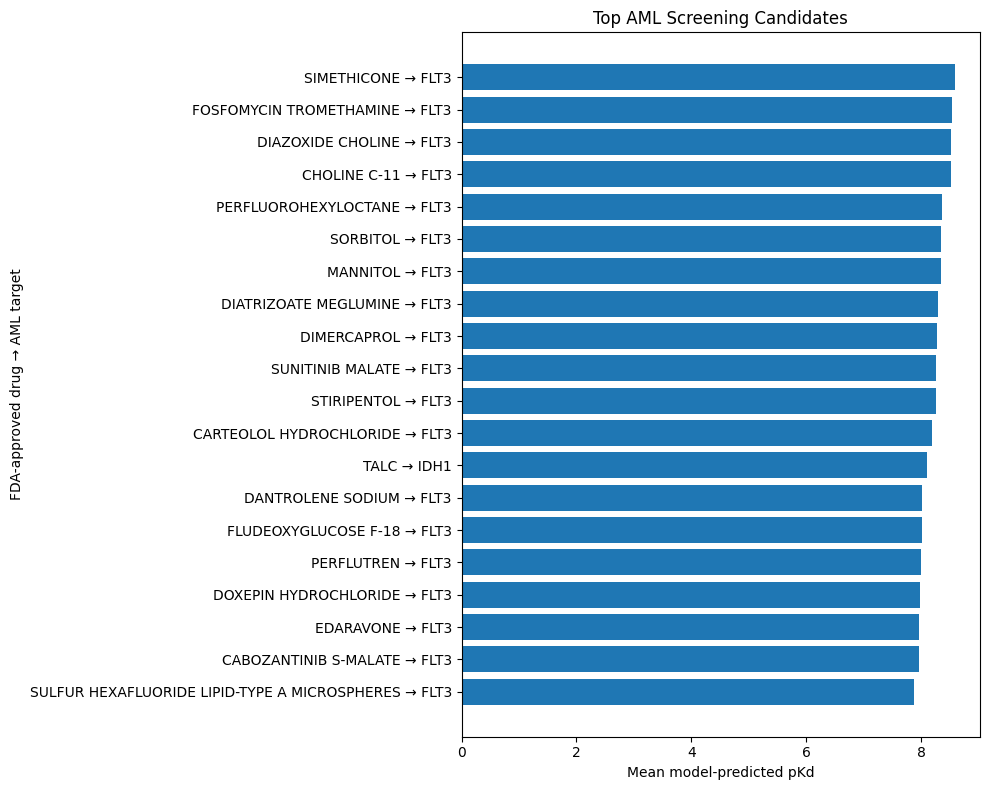

Figure saved to: /content/final-msc-dissertation-drug-repurposing/results/figures/aml_top20_unique_candidates.png


In [44]:
plot_df = (
    top_unique_drugs_df
    .sort_values(
        "mean_model_predicted_pkd",
        ascending=True,
    )
    .copy()
)

plot_labels = (
    plot_df["drug_name"]
    + " → "
    + plot_df["paper_target"]
)

plt.figure(
    figsize=(10, 8)
)

plt.barh(
    plot_labels,
    plot_df[
        "mean_model_predicted_pkd"
    ],
)

plt.xlabel(
    "Mean model-predicted pKd"
)

plt.ylabel(
    "FDA-approved drug → AML target"
)

plt.title(
    "Top AML Screening Candidates"
)

plt.tight_layout()

TOP_CANDIDATES_FIGURE = (
    RESULTS_DIR
    / "figures"
    / "aml_top20_unique_candidates.png"
)

TOP_CANDIDATES_FIGURE.parent.mkdir(
    parents=True,
    exist_ok=True,
)

plt.savefig(
    TOP_CANDIDATES_FIGURE,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print(
    "Figure saved to:",
    TOP_CANDIDATES_FIGURE,
)

## 36. Model agreement among the Top-20 consensus pairs

In [45]:
agreement_df = (
    consensus_top_df[
        [
            "drug_name",
            "paper_target",
            "baseline_predicted_pkd",
            "advanced_predicted_pkd",
        ]
    ]
    .copy()
)

agreement_df[
    "absolute_model_difference"
] = (
    agreement_df[
        "baseline_predicted_pkd"
    ]
    - agreement_df[
        "advanced_predicted_pkd"
    ]
).abs()

display(
    agreement_df
    .sort_values(
        "absolute_model_difference"
    )
    .round(4)
)

,drug_name,paper_target,baseline_predicted_pkd,advanced_predicted_pkd,absolute_model_difference
6,SUNITINIB MALATE,FLT3,8.2584,8.2456,0.0128
7,CARTEOLOL HYDROCHLORIDE,FLT3,8.2264,8.1533,0.0732
17,DOXEPIN HYDROCHLORIDE,FLT3,8.0420,7.9181,0.1239
14,DANTROLENE SODIUM,FLT3,8.1264,7.9170,0.2094
5,STIRIPENTOL,FLT3,8.3785,8.1224,0.2562
15,EDARAVONE,FLT3,8.2016,7.7347,0.4670
18,SULFUR HEXAFLUORIDE LIPID-TYPE A MICROSPHERES,FLT3,8.2797,7.4784,0.8013
16,CABOZANTINIB S-MALATE,FLT3,8.4030,7.5048,0.8982
13,PERFLUTREN,FLT3,8.5234,7.4815,1.0419
12,FLUDEOXYGLUCOSE F-18,FLT3,8.5505,7.4872,1.0633


## 37. Final screening summary

In [46]:
summary_df = pd.DataFrame(
    {
        "item": [
            "AML targets",
            "Primary small-molecule targets",
            "Exploratory targets",
            "FDA ingredients before PubChem/RDKit",
            "Final unique drug structures",
            "Drug-target pairs screened",
            "Selected baseline model",
            "Screening checkpoint split",
        ],
        "value": [
            len(aml_targets_df),
            int(
                (
                    aml_targets_df[
                        "screen_group"
                    ]
                    == "primary"
                ).sum()
            ),
            int(
                (
                    aml_targets_df[
                        "screen_group"
                    ]
                    == "exploratory"
                ).sum()
            ),
            len(fda_ingredients_df),
            len(candidate_drugs_df),
            len(screening_results_df),
            selected_baseline_name,
            SCREENING_SPLIT,
        ],
    }
)

display(summary_df)

print()
print("Saved data")
print("-" * 70)
print("AML targets:", AML_TARGETS_PATH)
print("FDA ingredients:", FDA_INGREDIENTS_PATH)
print("PubChem cache:", PUBCHEM_CACHE_PATH)
print("Candidate drugs:", CANDIDATE_DRUGS_PATH)
print("Structure audit:", CANDIDATE_AUDIT_PATH)

print()
print("Saved screening outputs")
print("-" * 70)
print("All predictions:", ALL_SCREENING_PATH)
print("Baseline Top-20:", BASELINE_TOP_PATH)
print("Advanced Top-20:", ADVANCED_TOP_PATH)
print("Consensus Top-20:", CONSENSUS_TOP_PATH)
print("Primary-target Top-20:", PRIMARY_TOP_PATH)
print("Top-10 per target:", TOP_PER_TARGET_PATH)
print("Top-20 unique drugs:", TOP_UNIQUE_DRUGS_PATH)
print("Figure:", TOP_CANDIDATES_FIGURE)

,item,value
0,AML targets,7
1,Primary small-molecule targets,5
2,Exploratory targets,2
3,FDA ingredients before PubChem/RDKit,1711
4,Final unique drug structures,1385
5,Drug-target pairs screened,9695
6,Selected baseline model,GIN + CNN
7,Screening checkpoint split,random



Saved data
----------------------------------------------------------------------
AML targets: /content/final-msc-dissertation-drug-repurposing/data/raw/aml/aml_targets.csv
FDA ingredients: /content/final-msc-dissertation-drug-repurposing/data/raw/aml/fda_active_ingredients.csv
PubChem cache: /content/final-msc-dissertation-drug-repurposing/data/raw/aml/pubchem_fda_lookup.csv
Candidate drugs: /content/final-msc-dissertation-drug-repurposing/data/raw/aml/candidate_drugs.csv
Structure audit: /content/final-msc-dissertation-drug-repurposing/data/raw/aml/candidate_drug_structure_audit.csv

Saved screening outputs
----------------------------------------------------------------------
All predictions: /content/final-msc-dissertation-drug-repurposing/results/predictions/aml_all_screening_predictions.csv
Baseline Top-20: /content/final-msc-dissertation-drug-repurposing/results/predictions/aml_baseline_top20_pairs.csv
Advanced Top-20: /content/final-msc-dissertation-drug-repurposing/results/pr

# Interpretation and limitations

This screening is designed for **hypothesis generation**, not biological or clinical confirmation.

Important points for the dissertation:

1. The seven AML targets are biologically motivated by the target review, while their model input sequences are independently verified as reviewed human UniProt entries.
2. The approved-drug library is based on active ingredients appearing in current RX/OTC products in the FDA Orange Book. It therefore reflects the scope of the Orange Book rather than every therapeutic biologic regulated by FDA.
3. PubChem supplies chemical structures; FDA remains the approval-status source.
4. PubChem structures are standardised with RDKit before molecular-graph construction. Duplicate standardised structures are removed.
5. The DTA models were trained on DAVIS. DAVIS is strongly kinase-oriented, so predictions for non-kinase targets such as BCL2, MEN1, CD123 and CD47 involve greater domain extrapolation than predictions for FLT3.
6. CD123 and CD47 are retained as exploratory targets because many therapeutic strategies directed at these cell-surface proteins are biologics rather than conventional small molecules.
7. Predicted pKd values are model outputs. They are not experimentally measured binding affinities.
8. High-ranked compounds may already have AML indications or known target interactions. These issues are investigated separately in the candidate-validation notebook.

The next notebook should therefore evaluate the highest-ranked candidates against independent evidence and existing clinical/therapeutic knowledge before any repurposing claim is made.

### Notebook completion

This notebook completes the **AML computational screening stage**:

```text
AML target review
      ↓
reviewed UniProt proteins
      +
FDA-approved active ingredients
      ↓
PubChem + RDKit structures
      ↓
best DAVIS baseline + advanced model
      ↓
predicted drug-target affinities
      ↓
model-specific and consensus rankings
      ↓
Top candidate drug-target pairs
      ↓
Top unique approved-drug candidates
```

The final ranked outputs are intentionally passed to Notebook 10 for independent candidate validation.